In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("brainsize.txt", sep="\t", na_values=["NA"])

features = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
df.head()

,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
0,Female,133,132,124,118.0,64.5,816932
1,Male,140,150,124,NaN,72.5,1001121
2,Male,139,123,150,143.0,73.3,1038437
3,Male,133,129,128,172.0,68.8,965353
4,Female,137,132,134,147.0,65.0,951545


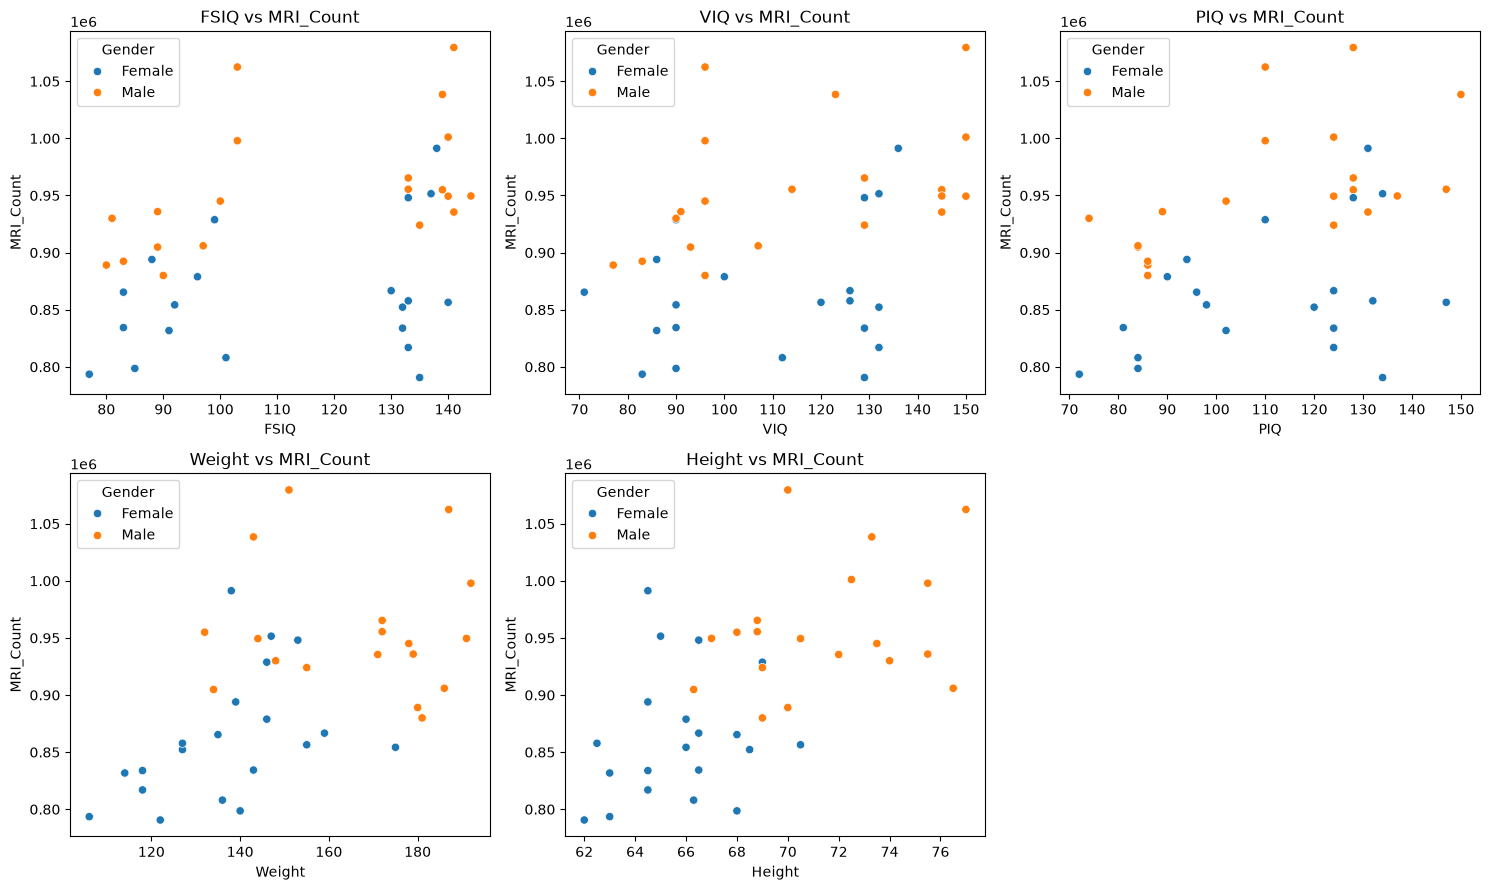

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, feature in enumerate(features):
    ax = axes.flat[i]
    sns.scatterplot(
        data=df,
        x=feature,
        y="MRI_Count",
        hue="Gender",
        ax=ax
    )
    ax.set_title(f"{feature} vs MRI_Count")

axes.flat[5].set_visible(False)
plt.tight_layout()
plt.show()

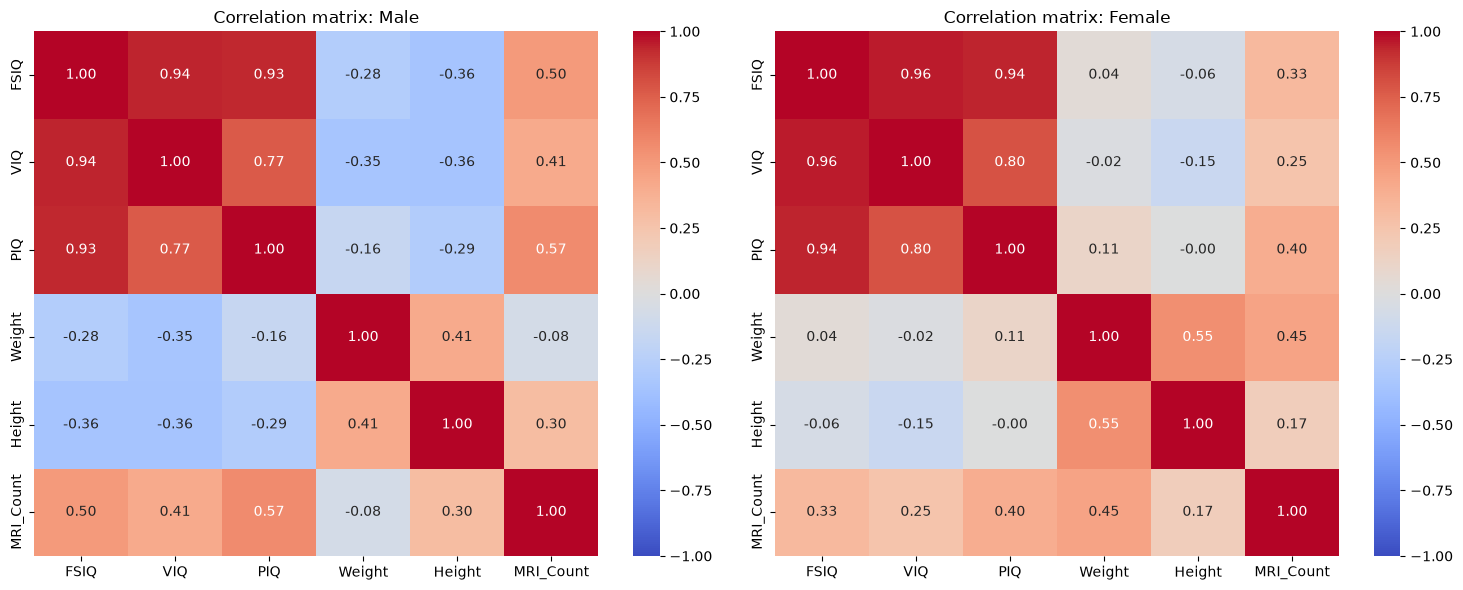

In [3]:
corr_features = features + ["MRI_Count"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, gender in zip(axes, ["Male", "Female"]):
    group = df[df["Gender"] == gender]
    corr_matrix = group[corr_features].corr(method="pearson")

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1,
        ax=ax
    )

    ax.set_title(f"Correlation matrix: {gender}")

plt.tight_layout()
plt.show()